# Model performance evaluation

This notebook evaluates the probabilities generated by the trained models on the **temporal test set**. The test set is treated as a final hold-out dataset: it is not used to fit models, select features, or choose thresholds.

## What is reported?

- **AUROC:** discrimination across all probability thresholds.
- **AUPRC:** precision-recall performance, particularly informative when ESBL events are uncommon.
- **Brier score:** overall accuracy of the predicted probabilities; lower is better.
- **Threshold metrics:** sensitivity, specificity, PPV, NPV, and F1 at the configured threshold.
- **Calibration:** whether predicted risks agree with observed ESBL frequencies.
- **Bootstrap intervals:** uncertainty around the test-set estimates.

The functions used here live in `icare_risk.evaluation`; this notebook is deliberately limited to loading data, declaring the evaluation assumptions, calling those functions, displaying results, and saving outputs.

## Interpretation and assumptions

1. Rows with missing, invalid, or unresolved outcomes are excluded by the reusable evaluation functions. Values such as `unknown` are not treated as non-ESBL.
2. The probability columns must contain values between 0 and 1.
3. The threshold is not optimised in this notebook. It is read from the configuration and should have been prespecified or selected using development data only.
4. Bootstrap intervals resample admissions independently. If patients contribute multiple admissions, patient-level bootstrap should be used for the final analysis.
5. Calibration estimates can be unstable when the test set is small or the number of ESBL events is low; always interpret them alongside sample size and event count.

In [45]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 3. Imports and setup

In [2]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

from sklearn.metrics import (
    roc_curve, auc,
    precision_recall_curve,
    average_precision_score
)

from icare_risk.evaluation import (
    bootstrap_prediction_table,
    calibration_table,
    compare_models,
    evaluate_calibration_table,
    evaluate_over_time,
    evaluate_prediction_table,
)

from icare_risk.evaluation import (
    evaluate_prediction_table,
    bootstrap_prediction_table,
    evaluate_calibration_table,
    plot_model_metrics,
)


warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)


In [3]:
CONFIG_PATH = Path('../src/icare_risk/config/icare/analysis.yaml')
with CONFIG_PATH.open() as handle:
    config = yaml.safe_load(handle)

target = config["columns"]["target"]
date_column = config["columns"]["admission_date"]
target_mapping = config.get("target_mapping", {})
OUTPUTS = config["outputs"]

prediction_directory = Path(OUTPUTS.get("prediction_directory"))
metrics_directory = Path(OUTPUTS.get("metrics_directory"))

prediction_path = prediction_directory / "admission_predictions.parquet"
if not prediction_path.exists():
    prediction_path = prediction_directory / "admission_predictions.csv"

predictions = (
    pd.read_parquet(prediction_path)
    if prediction_path.suffix == ".parquet"
    else pd.read_csv(prediction_path)
)

prediction_columns = [
    column for column in predictions.columns if column.endswith("_prob")
]
if not prediction_columns:
    raise ValueError("No prediction columns ending in '_prob' were found.")

print(f"Loaded: {prediction_path}")
print(f"Rows: {len(predictions):,}")
print(f"Prediction columns: {len(prediction_columns)}")
for c in prediction_columns:
    print(f"  - {c}")


Loaded: results/predictions/admission_predictions.parquet
Rows: 10,000
Prediction columns: 6
  - lr_kim_components_prob
  - lr_all_score_values_prob
  - lr_clinical_baseline_prob
  - xgb_kim_components_prob
  - xgb_all_score_values_prob
  - xgb_clinical_baseline_prob


## Define the evaluation cohort

The primary analysis uses the untouched temporal test set. If the prediction table does not contain a `split` column, all rows are used and a warning is displayed.


In [4]:
if "split" in predictions.columns:
    test_mask = predictions["split"].eq("test")
    if test_mask.sum() == 0:
        raise ValueError(
            "The prediction table contains a 'split' column but no rows labelled 'test'."
        )
else:
    test_mask = pd.Series(True, index=predictions.index)
    print("Warning: no 'split' column found; evaluating all rows.")

print(f"Evaluation rows: {test_mask.sum():,}")


Evaluation rows: 2,483


## Point estimates

These are the observed test-set performance estimates at the configured threshold. AUROC, AUPRC, and Brier score use the continuous predicted probabilities; sensitivity and related classification measures use the fixed threshold.


In [5]:
# The initial evaluation threshold.
THRESHOLD = config['analysis'].get('evaluation_threshold')

point_metrics = evaluate_prediction_table(
    predictions,
    target_column=target,
    prediction_columns=prediction_columns,
    subset=test_mask,
    threshold=THRESHOLD,
    target_mapping=target_mapping,
)

display(
    point_metrics \
        .sort_values('auroc', ascending=False) \
        .reset_index(drop=True)
)


,model,prediction_column,n,n_events,event_rate,auroc,auprc,brier_score,threshold,tp,tn,fp,fn,sensitivity,specificity,ppv,npv,accuracy,balanced_accuracy,f1
0,lr_clinical_baseline,lr_clinical_baseline_prob,2483,493,0.19855,0.524319,0.214954,0.249272,0.5,249,1054,936,244,0.505071,0.529648,0.210127,0.812018,0.524768,0.517360,0.296782
1,xgb_clinical_baseline,xgb_clinical_baseline_prob,2483,493,0.19855,0.513289,0.206194,0.160715,0.5,0,1990,0,493,0.000000,1.000000,0.000000,0.801450,0.801450,0.500000,0.000000
2,lr_all_score_values,lr_all_score_values_prob,2483,493,0.19855,0.507790,0.202931,0.250551,0.5,69,1715,275,424,0.139959,0.861809,0.200581,0.801777,0.718486,0.500884,0.164875
3,lr_kim_components,lr_kim_components_prob,2483,493,0.19855,0.500189,0.198699,0.250131,0.5,56,1770,220,437,0.113590,0.889447,0.202899,0.801994,0.735401,0.501519,0.145644
4,xgb_kim_components,xgb_kim_components_prob,2483,493,0.19855,0.500189,0.198699,0.159200,0.5,0,1990,0,493,0.000000,1.000000,0.000000,0.801450,0.801450,0.500000,0.000000
5,xgb_all_score_values,xgb_all_score_values_prob,2483,493,0.19855,0.499755,0.207303,0.159342,0.5,0,1990,0,493,0.000000,1.000000,0.000000,0.801450,0.801450,0.500000,0.000000


## Bootstrap confidence intervals

Bootstrap resampling estimates how much the reported test-set metrics could vary because only a finite number of admissions were observed. The intervals are percentile intervals and should not be interpreted as replacing external validation.

For the primary manuscript analysis, consider replacing admission-level resampling with patient-level resampling if patients contribute multiple admissions.


In [6]:
N_BOOTSTRAPS = 200

metrics_ci = bootstrap_prediction_table(
    predictions,
    target_column=target,
    prediction_columns=prediction_columns,
    subset=test_mask,
    n_bootstraps=N_BOOTSTRAPS,
    ci=0.95,
    threshold=THRESHOLD,
    target_mapping=target_mapping,
    random_state=42,
)

display(
    metrics_ci \
        .sort_values('auroc', ascending=False) \
        .reset_index(drop=True)
)

,model,prediction_column,n,n_events,event_rate,auroc,auprc,brier_score,threshold,tp,tn,fp,fn,sensitivity,specificity,ppv,npv,accuracy,balanced_accuracy,f1,auroc_ci_lower,auroc_ci_upper,auprc_ci_lower,auprc_ci_upper,brier_score_ci_lower,brier_score_ci_upper,sensitivity_ci_lower,sensitivity_ci_upper,specificity_ci_lower,specificity_ci_upper,ppv_ci_lower,ppv_ci_upper,npv_ci_lower,npv_ci_upper,accuracy_ci_lower,accuracy_ci_upper,balanced_accuracy_ci_lower,balanced_accuracy_ci_upper,f1_ci_lower,f1_ci_upper,n_bootstraps_requested,n_bootstraps_valid
0,lr_clinical_baseline,lr_clinical_baseline_prob,2483,493,0.19855,0.524319,0.214954,0.249272,0.5,249,1054,936,244,0.505071,0.529648,0.210127,0.812018,0.524768,0.517360,0.296782,0.494666,0.552188,0.192283,0.244388,0.247932,0.251129,0.458502,0.551676,0.508216,0.549219,0.184916,0.235570,0.788293,0.832608,0.503423,0.544915,0.491013,0.544221,0.264712,0.330683,200,200
1,xgb_clinical_baseline,xgb_clinical_baseline_prob,2483,493,0.19855,0.513289,0.206194,0.160715,0.5,0,1990,0,493,0.000000,1.000000,0.000000,0.801450,0.801450,0.500000,0.000000,0.485742,0.539978,0.185512,0.230184,0.151684,0.172862,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.781706,0.816391,0.781706,0.816391,0.500000,0.500000,0.000000,0.000000,200,200
2,lr_all_score_values,lr_all_score_values_prob,2483,493,0.19855,0.507790,0.202931,0.250551,0.5,69,1715,275,424,0.139959,0.861809,0.200581,0.801777,0.718486,0.500884,0.164875,0.473690,0.533620,0.182299,0.226165,0.250035,0.251042,0.109485,0.169778,0.847896,0.874636,0.163488,0.243456,0.786345,0.814925,0.700362,0.733035,0.484206,0.516176,0.131508,0.195316,200,200
3,lr_kim_components,lr_kim_components_prob,2483,493,0.19855,0.500189,0.198699,0.250131,0.5,56,1770,220,437,0.113590,0.889447,0.202899,0.801994,0.735401,0.501519,0.145644,0.484808,0.517777,0.183192,0.216178,0.249510,0.250680,0.088658,0.144422,0.873727,0.903863,0.153285,0.249066,0.786160,0.818240,0.717267,0.753937,0.486511,0.518677,0.113798,0.181837,200,200
4,xgb_kim_components,xgb_kim_components_prob,2483,493,0.19855,0.500189,0.198699,0.159200,0.5,0,1990,0,493,0.000000,1.000000,0.000000,0.801450,0.801450,0.500000,0.000000,0.485790,0.515243,0.183017,0.215557,0.150743,0.168433,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.786146,0.815556,0.786146,0.815556,0.500000,0.500000,0.000000,0.000000,200,200
5,xgb_all_score_values,xgb_all_score_values_prob,2483,493,0.19855,0.499755,0.207303,0.159342,0.5,0,1990,0,493,0.000000,1.000000,0.000000,0.801450,0.801450,0.500000,0.000000,0.474141,0.521838,0.187023,0.226946,0.151564,0.167963,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.787757,0.814750,0.787757,0.814750,0.500000,0.500000,0.000000,0.000000,200,200


## Calibration

Calibration asks whether a group of admissions predicted to have, for example, 20% risk actually contains approximately 20% ESBL events. A model can discriminate well but still be poorly calibrated.

- Calibration intercept: ideal value is 0.
- Calibration slope: ideal value is 1.
- Observed/expected ratio: ideal value is 1.
- Brier score: lower values indicate better probabilistic accuracy.


In [7]:
calibration_metrics = evaluate_calibration_table(
    predictions,
    target_column=target,
    prediction_columns=prediction_columns,
    subset=test_mask,
    n_bins=10,
    strategy="quantile",
    target_mapping=target_mapping,
)

display(
    calibration_metrics \
        .sort_values('brier_score', ascending=True) \
        .reset_index(drop=True)
)

metrics_directory.mkdir(parents=True, exist_ok=True)

point_metrics.to_csv(metrics_directory / "test_point_metrics.csv", index=False)
metrics_ci.to_csv(metrics_directory / "test_performance_bootstrap.csv", index=False)
calibration_metrics.to_csv(metrics_directory / "test_calibration_metrics.csv", index=False)

print(f"Saved all evaluation results to {metrics_directory}")

,model,prediction_column,n,n_events,brier_score,calibration_intercept,calibration_slope,observed_expected_ratio
0,xgb_kim_components,xgb_kim_components_prob,2483,493,0.159200,-1.242315,0.108346,1.013446
1,xgb_all_score_values,xgb_all_score_values_prob,2483,493,0.159342,-1.102098,0.205036,1.025580
2,xgb_clinical_baseline,xgb_clinical_baseline_prob,2483,493,0.160715,-1.323472,0.050593,1.009802
3,lr_clinical_baseline,lr_clinical_baseline_prob,2483,493,0.249272,-1.394259,0.628674,0.398511
4,lr_kim_components,lr_kim_components_prob,2483,493,0.250131,-1.395133,0.001655,0.397135
5,lr_all_score_values,lr_all_score_values_prob,2483,493,0.250551,-1.395123,-0.003334,0.396641


Saved all evaluation results to results/metrics


## Visual comparison of models

Small-multiple plots keep metrics with different interpretations separate. Discrimination metrics, calibration metrics, and fixed-threshold metrics should not be placed on one shared axis.

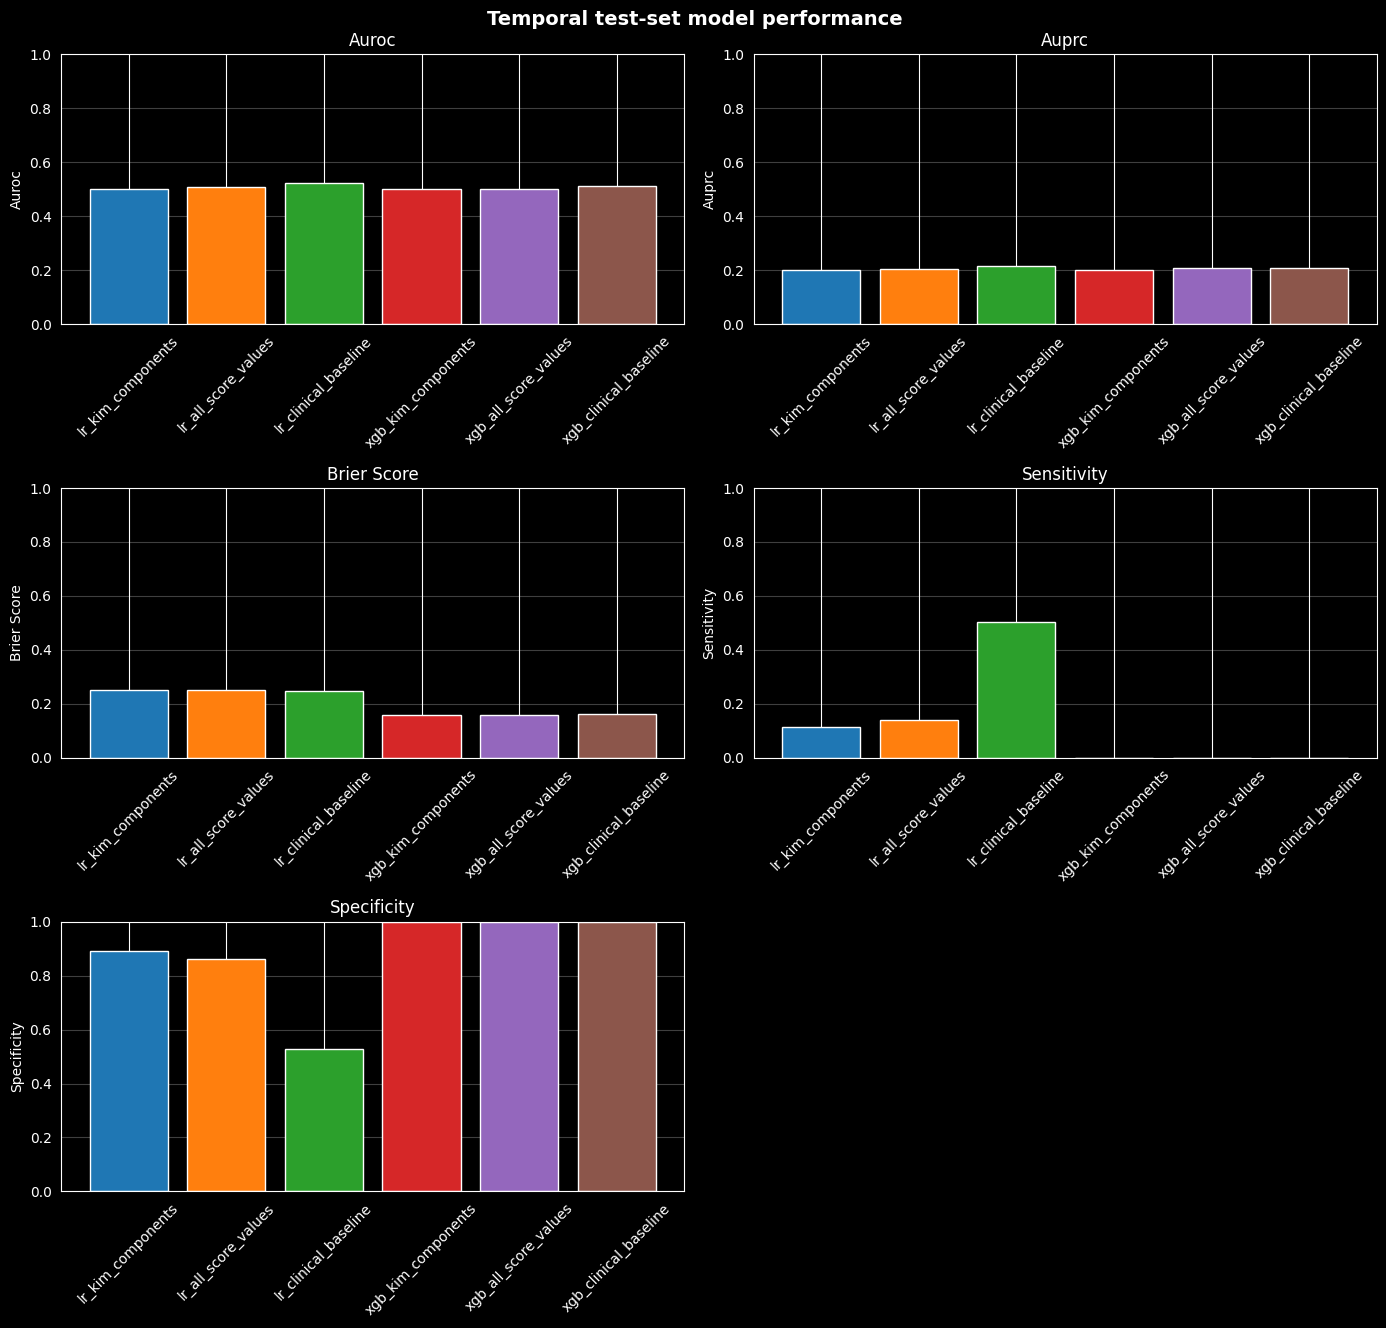

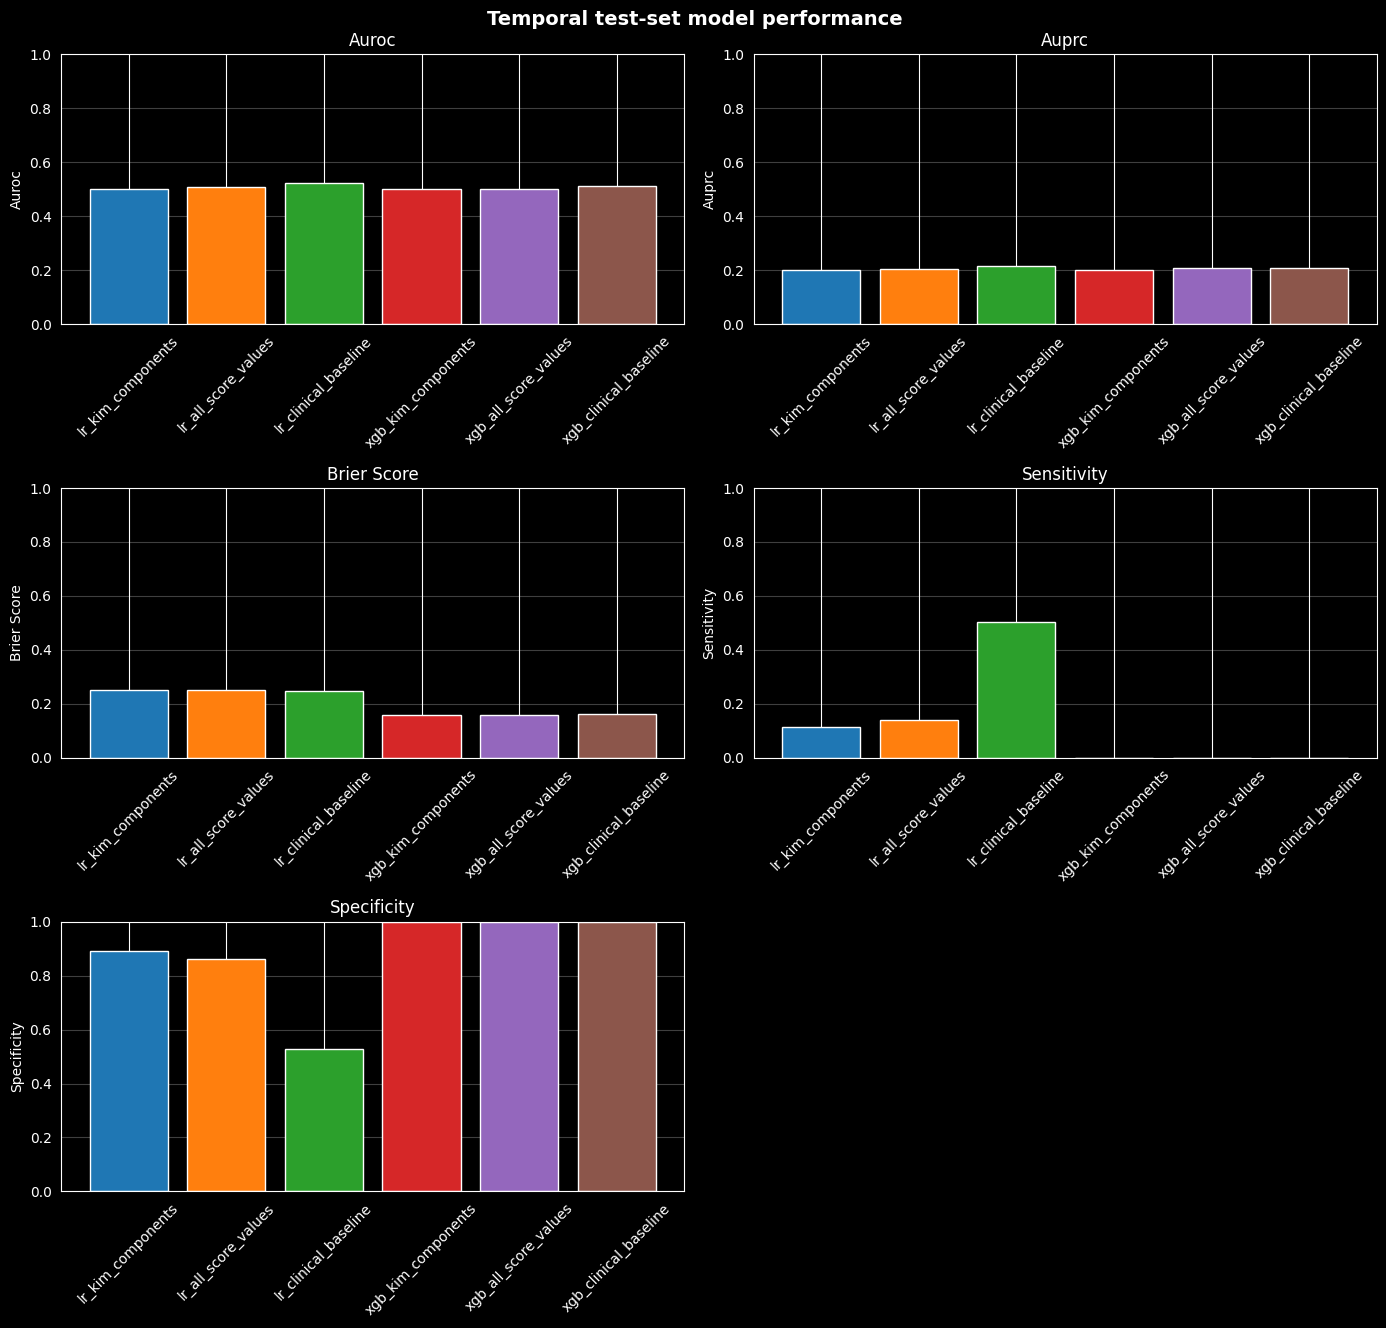

In [10]:
from icare_risk.evaluation import (
    plot_model_metrics,
)

PLOT_METRICS = [
    'auroc', 'auprc', 'brier_score', 'sensitivity', 'specificity'
]

performance_figure = plot_model_metrics(
    point_metrics,
    metrics=PLOT_METRICS,
    title='Temporal test-set model performance',
    y_limits={metric: (0, 1) for metric in PLOT_METRICS},
)
display(performance_figure)

## Advanced visual comparisons and curves

This section generates publication-ready visual diagnostics for model comparison on the temporal test set:

1. **Small-Multiple Metric Bar Plots (`plot_model_metrics`)**: Summarises point estimates across key performance indicators (AUROC, AUPRC, Brier score, sensitivity, and specificity) for a clean side-by-side comparison.
2. **Receiver Operating Characteristic (ROC) Curves**: Illustrates the trade-off between the True Positive Rate and False Positive Rate across all possible classification thresholds, displaying the Area Under the Curve (ROC-AUC) for each model.
3. **Precision-Recall (PR) Curves**: Evaluates performance under class imbalance (critical when ESBL events are relatively uncommon), plotting Precision against Recall alongside the baseline event rate and Average Precision (AP) scores.

Filtered evaluation rows for plotting: 0
Positive class prevalence: nan%


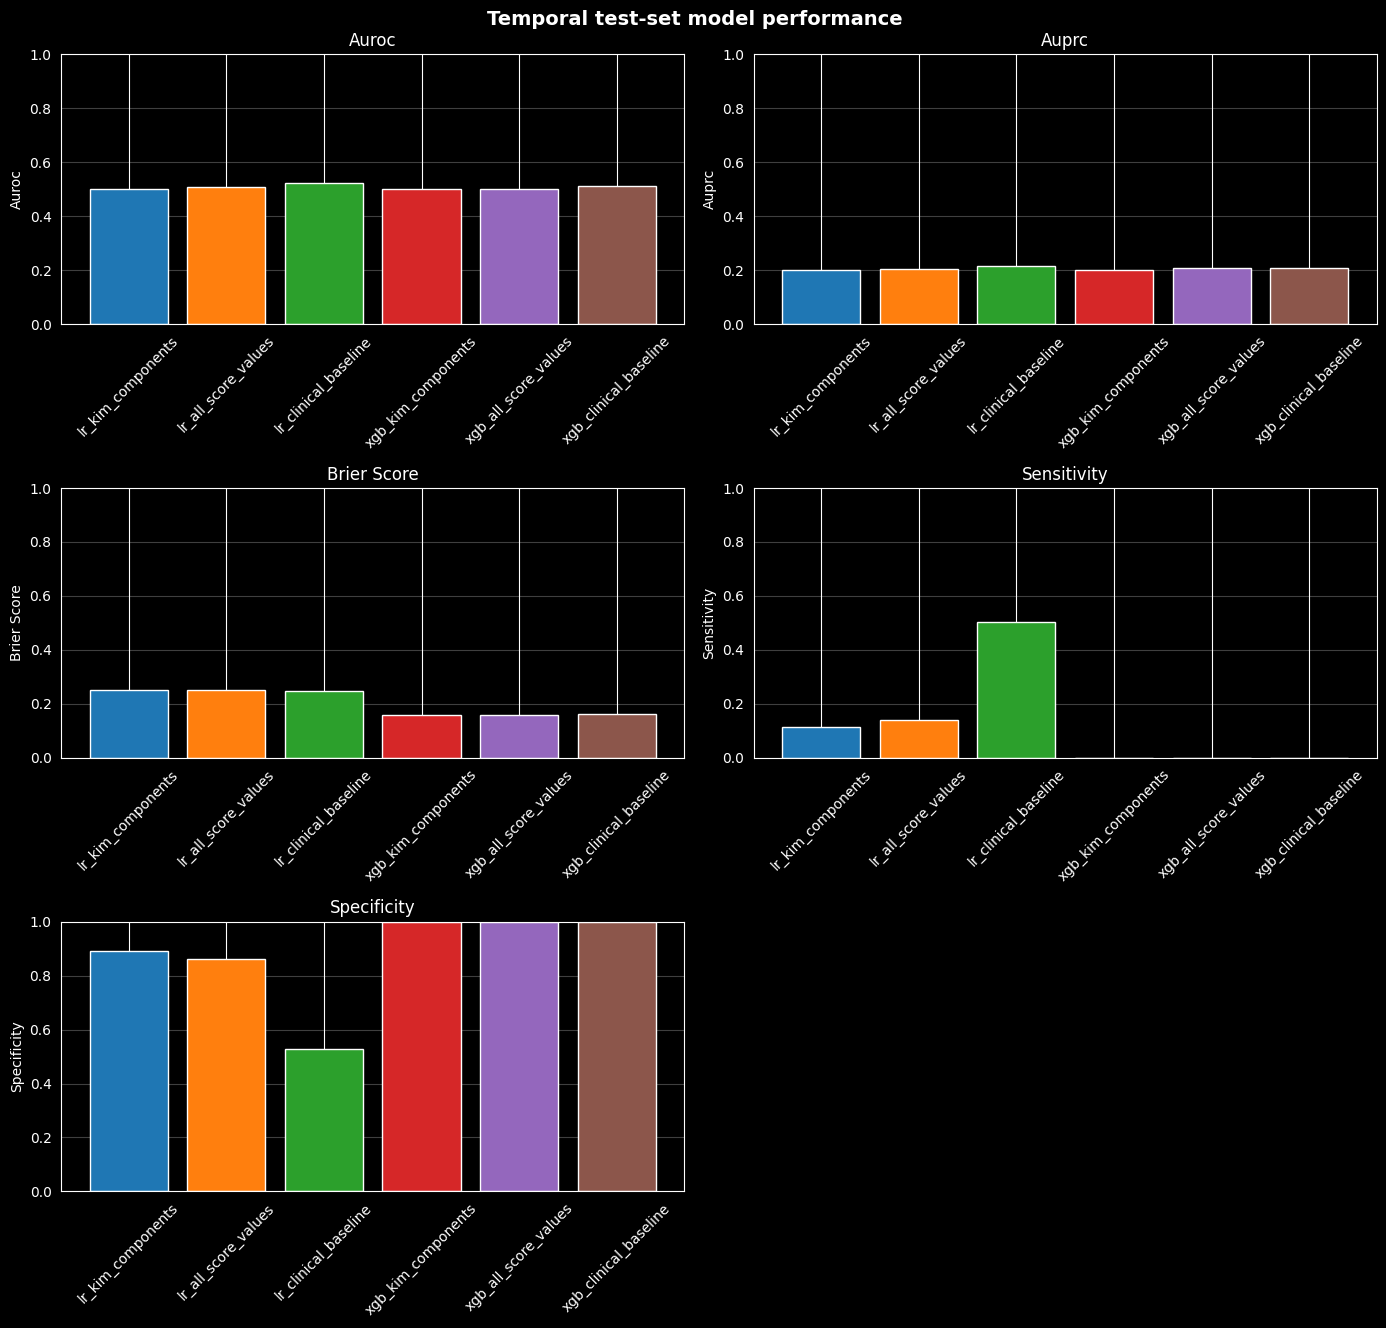

ValueError: y_true takes value in {} and pos_label is not specified: either make y_true take value in {0, 1} or {-1, 1} or pass pos_label explicitly.

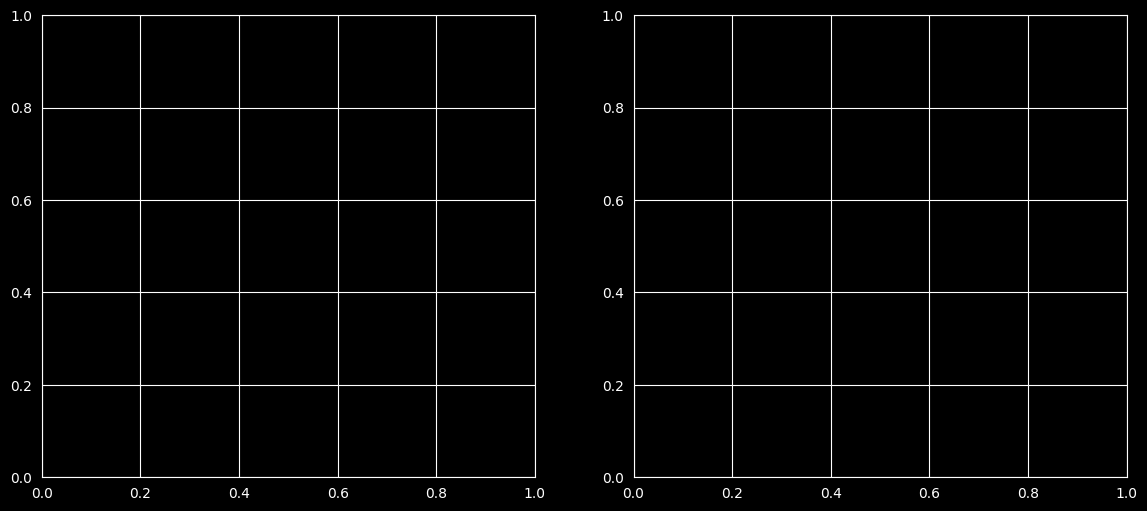

In [12]:
# Prepare data for advanced curves using icare_risk's internal mapping logic
eval_df = predictions[test_mask].copy()

# Extract target and apply mapping if available
raw_y = eval_df[target]
if target_mapping:
    y_true = raw_y.map(target_mapping)
else:
    y_true = raw_y

# Drop NaNs safely across both true labels and predictions
valid_mask = y_true.notna()
for col in prediction_columns:
    valid_mask &= eval_df[col].notna()

eval_df = eval_df[valid_mask]
y_true = y_true[valid_mask].astype(int)

print(f"Filtered evaluation rows for plotting: {len(eval_df):,}")
print(f"Positive class prevalence: {y_true.mean():.3%}")

# 1. Small-multiple metric comparison bars
PLOT_METRICS = [
    'auroc', 'auprc', 'brier_score', 'sensitivity', 'specificity'
]

performance_figure = plot_model_metrics(
    point_metrics,
    metrics=PLOT_METRICS,
    title='Temporal test-set model performance',
    y_limits={metric: (0, 1) for metric in PLOT_METRICS},
)
plt.show()

# 2. ROC and PR Curves Multi-panel Figure
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for col in prediction_columns:
    y_prob = eval_df[col]
    model_name = col.replace('_prob', '')

    # ROC Curve
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    roc_auc = auc(fpr, tpr)
    axes[0].plot(fpr, tpr, label=f"{model_name} (AUC = {roc_auc:.3f})")

axes[0].plot([0, 1], [0, 1], 'k--', lw=1)
axes[0].set_xlim([0.0, 1.0])
axes[0].set_ylim([0.0, 1.05])
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('Receiver Operating Characteristic (ROC)')
axes[0].legend(loc='lower right', fontsize=8)
axes[0].grid(True, alpha=0.3)

# PR Curve
baseline_rate = y_true.mean()
for col in prediction_columns:
    y_prob = eval_df[col]
    model_name = col.replace('_prob', '')
    precision, recall, _ = precision_recall_curve(y_true, y_prob)
    pr_auc = average_precision_score(y_true, y_prob)
    axes[1].plot(recall, precision, label=f"{model_name} (AP = {pr_auc:.3f})")

axes[1].axhline(y=baseline_rate, color='k', linestyle='--', lw=1, label=f'Baseline ({baseline_rate:.3f})')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall Curve (PR)')
axes[1].legend(loc='upper right', fontsize=8)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

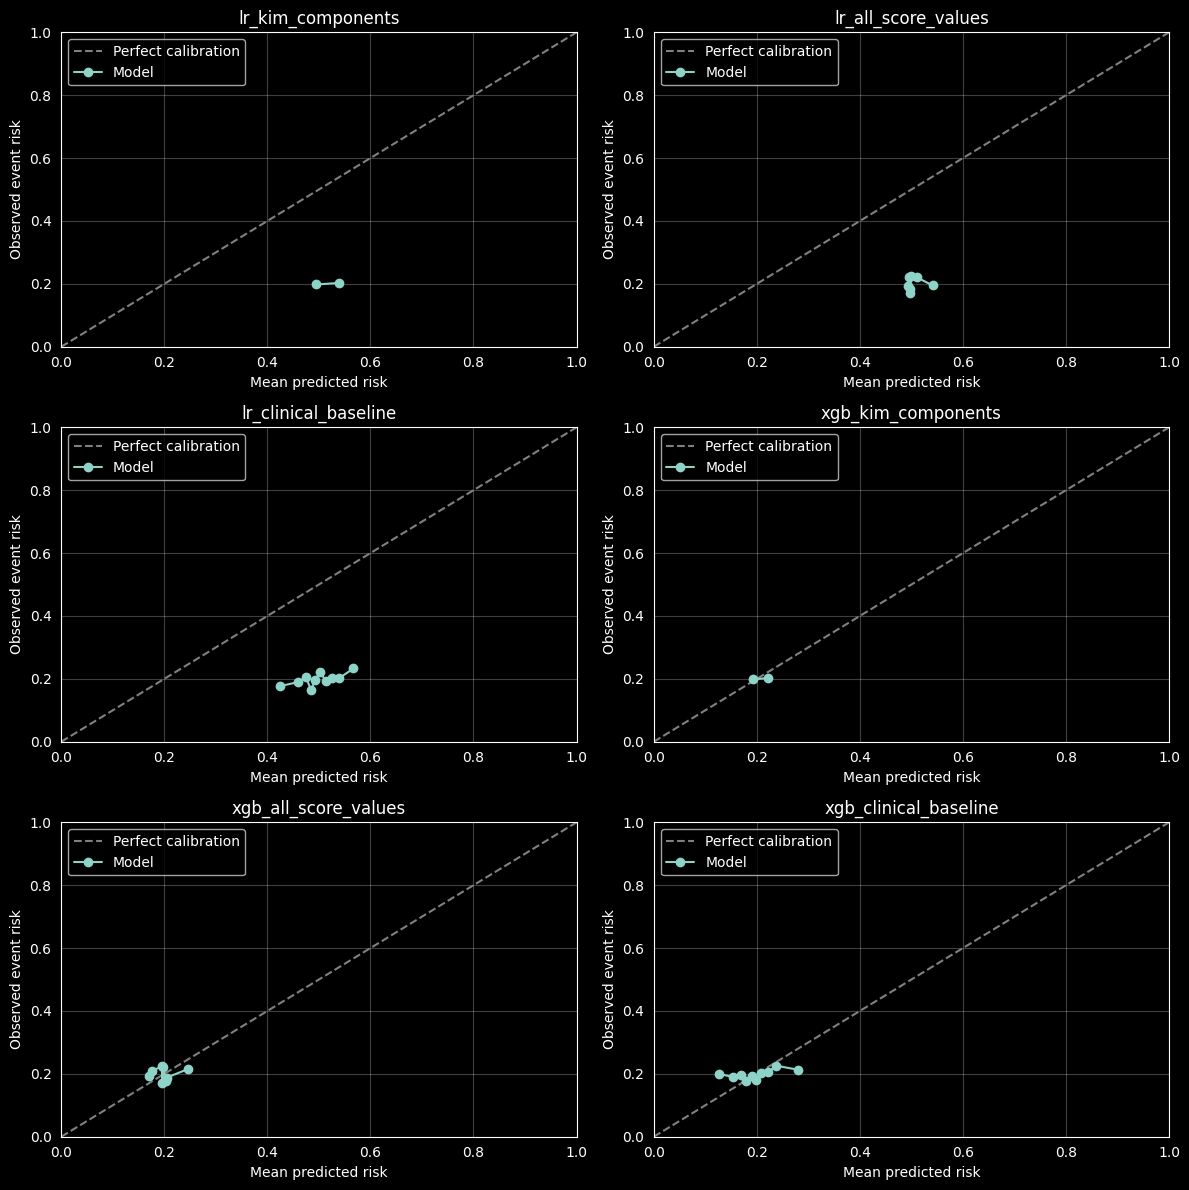

In [70]:
n_models = len(prediction_columns)
n_columns = 2
n_rows = (n_models + n_columns - 1) // n_columns
fig, axes = plt.subplots(
    n_rows, n_columns, figsize=(12, 4 * n_rows), squeeze=False
)

for ax, prediction_column in zip(axes.flat, prediction_columns):
    table = calibration_table(
        predictions.loc[test_mask, target],
        predictions.loc[test_mask, prediction_column],
        n_bins=10,
        strategy="quantile",
        target_mapping=target_mapping,
    )
    ax.plot([0, 1], [0, 1], "--", color="grey", label="Perfect calibration")
    ax.plot(
        table["mean_predicted_risk"],
        table["observed_risk"],
        "o-",
        label="Model",
    )
    ax.set_title(prediction_column.removesuffix("_prob"))
    ax.set_xlabel("Mean predicted risk")
    ax.set_ylabel("Observed event risk")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.legend()
    ax.grid(alpha=0.25)

for ax in axes.flat[len(prediction_columns):]:
    ax.remove()

fig.tight_layout()
fig.savefig(
    metrics_directory / "test_calibration_plots.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


## Performance over calendar time

This is descriptive temporal monitoring within the available prediction table. The primary temporal hold-out comparison remains the test-set result above.


In [57]:
temporal = evaluate_over_time(
    predictions.loc[test_mask],
    date_column=date_column,
    target_column=target,
    prediction_columns=prediction_columns,
    freq=config.get("analysis", {}).get("temporal_frequency", "YS"),
    threshold=THRESHOLD,
    target_mapping=target_mapping,
)

temporal.to_csv(
    metrics_directory / "test_temporal_performance.csv", index=False
)
display(temporal)


,period,period_label,model,prediction_column,n,n_events,event_rate,auroc,auprc,brier_score,threshold,tp,tn,fp,fn,sensitivity,specificity,ppv,npv,accuracy,balanced_accuracy,f1
0,2022-01-01,2022-01-01,lr_kim_components,lr_kim_components_prob,6,0,0.000000,NaN,NaN,NaN,0.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2022-01-01,2022-01-01,lr_all_score_values,lr_all_score_values_prob,6,0,0.000000,NaN,NaN,NaN,0.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2022-01-01,2022-01-01,lr_clinical_baseline,lr_clinical_baseline_prob,6,0,0.000000,NaN,NaN,NaN,0.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2022-01-01,2022-01-01,xgb_kim_components,xgb_kim_components_prob,6,0,0.000000,NaN,NaN,NaN,0.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2022-01-01,2022-01-01,xgb_all_score_values,xgb_all_score_values_prob,6,0,0.000000,NaN,NaN,NaN,0.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,2022-01-01,2022-01-01,xgb_clinical_baseline,xgb_clinical_baseline_prob,6,0,0.000000,NaN,NaN,NaN,0.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,2023-01-01,2023-01-01,lr_kim_components,lr_kim_components_prob,2472,493,0.199434,0.500137,0.199566,0.250135,0.5,56.0,1760.0,219.0,437.0,0.113590,0.889338,0.203636,0.801092,0.734628,0.501464,0.145833
7,2023-01-01,2023-01-01,lr_all_score_values,lr_all_score_values_prob,2472,493,0.199434,0.507482,0.203656,0.250561,0.5,69.0,1705.0,274.0,424.0,0.139959,0.861546,0.201166,0.800845,0.717638,0.500753,0.165072
8,2023-01-01,2023-01-01,lr_clinical_baseline,lr_clinical_baseline_prob,2472,493,0.199434,0.524572,0.215865,0.249257,0.5,249.0,1049.0,930.0,244.0,0.505071,0.530066,0.211196,0.811292,0.525081,0.517568,0.297847
9,2023-01-01,2023-01-01,xgb_kim_components,xgb_kim_components_prob,2472,493,0.199434,0.500137,0.199566,0.159738,0.5,0.0,1979.0,0.0,493.0,0.000000,1.000000,0.000000,0.800566,0.800566,0.500000,0.000000


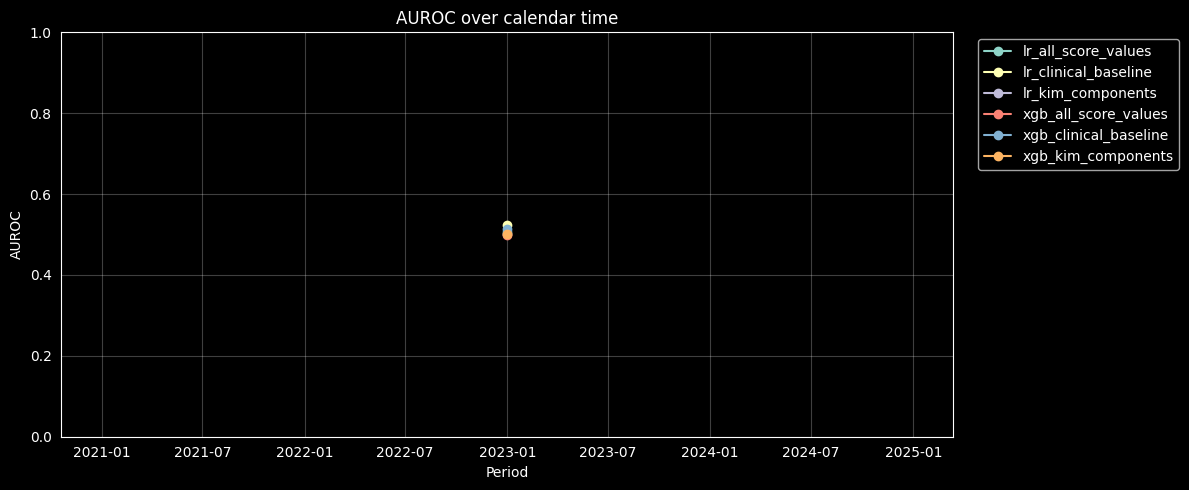

In [58]:
if not temporal.empty:
    fig, ax = plt.subplots(figsize=(12, 5))
    for model, group in temporal.groupby("model"):
        ax.plot(group["period"], group["auroc"], marker="o", label=model)
    ax.set_title("AUROC over calendar time")
    ax.set_xlabel("Period")
    ax.set_ylabel("AUROC")
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.25)
    ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
    fig.tight_layout()
    fig.savefig(
        metrics_directory / "test_temporal_auroc.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()


## Combined model summary

Use this table for an initial comparison only. Final reporting should specify the prespecified threshold, confidence interval method, outcome exclusions, and whether resampling was performed at patient or admission level.


In [44]:
summary = performance.merge(
    calibration_metrics[
        [
            "model",
            "calibration_intercept",
            "calibration_slope",
            "observed_expected_ratio",
        ]
    ],
    on="model",
    how="left",
)

summary = summary.sort_values("auroc", ascending=False)
display(summary)
summary.to_csv(metrics_directory / "test_model_summary.csv", index=False)


,model,prediction_column,n,n_events,event_rate,auroc,auprc,brier_score,threshold,tp,tn,fp,fn,sensitivity,specificity,ppv,npv,accuracy,balanced_accuracy,f1,auroc_ci_lower,auroc_ci_upper,auprc_ci_lower,auprc_ci_upper,brier_score_ci_lower,brier_score_ci_upper,sensitivity_ci_lower,sensitivity_ci_upper,specificity_ci_lower,specificity_ci_upper,ppv_ci_lower,ppv_ci_upper,npv_ci_lower,npv_ci_upper,accuracy_ci_lower,accuracy_ci_upper,balanced_accuracy_ci_lower,balanced_accuracy_ci_upper,f1_ci_lower,f1_ci_upper,n_bootstraps_requested,n_bootstraps_valid,calibration_intercept,calibration_slope,observed_expected_ratio
0,lr_clinical_baseline,lr_clinical_baseline_prob,2483,508,0.204591,0.521869,0.215387,0.248659,0.5,259,1001,974,249,0.509843,0.506835,0.210057,0.800800,0.507451,0.508339,0.297530,0.493329,0.547660,0.195756,0.244005,0.247211,0.250374,0.465729,0.548939,0.486825,0.529250,0.187081,0.229778,0.777683,0.822026,0.486085,0.526379,0.482883,0.529436,0.268673,0.321990,200,200,-1.353805,0.544682,0.411742
1,xgb_clinical_baseline,xgb_clinical_baseline_prob,2483,508,0.204591,0.514920,0.219864,0.164069,0.5,0,1975,0,508,0.000000,1.000000,0.000000,0.795409,0.795409,0.500000,0.000000,0.488928,0.543654,0.200285,0.249098,0.154011,0.174334,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.778474,0.811166,0.778474,0.811166,0.500000,0.500000,0.000000,0.000000,200,200,-1.033741,0.220184,1.076944
2,xgb_all_scores,xgb_all_scores_prob,2483,508,0.204591,0.509264,0.210962,0.163140,0.5,0,1975,0,508,0.000000,1.000000,0.000000,0.795409,0.795409,0.500000,0.000000,0.483201,0.537116,0.188742,0.230594,0.153401,0.172298,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.781313,0.811549,0.781313,0.811549,0.500000,0.500000,0.000000,0.000000,200,200,-1.065966,0.201427,1.071928
3,lr_kim_score,lr_kim_score_prob,2483,508,0.204591,0.495556,0.203157,0.249759,0.5,447,219,1756,61,0.879921,0.110886,0.202905,0.782143,0.268224,0.495404,0.329768,0.480312,0.513171,0.187806,0.220576,0.249327,0.250089,0.851309,0.910520,0.097002,0.128065,0.186881,0.220495,0.734105,0.832811,0.252114,0.286377,0.480125,0.513050,0.308134,0.352570,200,200,-1.357386,1.077531,0.409520
4,xgb_kim_score,xgb_kim_score_prob,2483,508,0.204591,0.495556,0.203157,0.162869,0.5,0,1975,0,508,0.000000,1.000000,0.000000,0.795409,0.795409,0.500000,0.000000,0.481066,0.508998,0.185890,0.220503,0.152919,0.172808,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.779289,0.811538,0.779289,0.811538,0.500000,0.500000,0.000000,0.000000,200,200,-0.441228,0.636857,1.067865
5,lr_all_scores,lr_all_scores_prob,2483,508,0.204591,0.488996,0.198725,0.248381,0.5,241,995,980,267,0.474409,0.503797,0.197379,0.788431,0.497785,0.489103,0.278774,0.460927,0.513718,0.178735,0.217604,0.247707,0.249090,0.430375,0.514621,0.485579,0.526790,0.172107,0.219681,0.762494,0.809710,0.479219,0.519936,0.466390,0.514951,0.248125,0.306394,200,200,-1.353105,0.372360,0.411947
